In [34]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from features import add_derived, LABEL, HEURISTIC, POOL, cols
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.linear_model import lars_path
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator
from sklearn.linear_model import LassoCV

### We begin by reading all of our columns/data in and prepare our folds:

In [35]:
# Set seed
SEED = 6021

# Add feature engineered columns (MARINE_N3, Natural_Sugar, Legumes, F_Whole, Veg_Other_NS) based on EDA
df = add_derived(pd.read_csv("data/processed/analytic_cohort.csv"))

# Transform MET in accordance with EDA
# Log Transform + Activity indicator 
df["LOG_MET"] = np.log1p(df["MET_MIN_WK"])
df["ANY_PA"] = (df["MET_MIN_WK"] > 0).astype(float).where(df["MET_MIN_WK"].notna())

# Isolate HbA1C, make sure none of outcomes are missing
y = df["LBXGH"]
assert y.notna().all()

# Isolate controls by type
CTRL_NUM = ["RIDAGEYR", "INDFMPIR", "LOG_MET", "ANY_PA", "SED_MIN"]
CTRL_CAT = ["RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMOKING", "FSDHH"]

# Isolate feature sets for each model
# Check that sizes match
POOL_COLS = cols(POOL)
SETS = {
    "B0": [],
    "Label": ["KCAL"] + cols(LABEL),
    "Heuristic": ["KCAL"] + cols(HEURISTIC),
    "B1": ["KCAL"] + cols(POOL),
}
assert all(len(SETS[s]) == 14 for s in ["Label", "Heuristic"]) and len(SETS["B1"]) == 84

# Read in feature costs, make a column vector containing them
# Also check that pool is a subset of the costs
cost = pd.read_csv("data/processed/discursive_cost.csv", index_col="feature")["cost"]
assert set(POOL) <= set(cost.index)

# Create an hba1c bin group to stratify the data
# Create and assign data to folds
hba1c_group = pd.cut(y, bins=[-np.inf, 5.7, 6.5, np.inf], right=False, labels=["normal", "pre", "high"])
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
df["FOLD"] = -1
for k, (_, test) in enumerate(outer.split(df, hba1c_group)):
    df.loc[df.index[test], "FOLD"] = k

# Output summary
print(df.shape)
print(pd.crosstab(df["FOLD"], hba1c_group))

(3286, 315)
LBXGH  normal  pre  high
FOLD                    
0         425  209    24
1         425  209    23
2         425  209    23
3         425  209    23
4         424  209    24


### Here are some reusable functions for the preprocessing, model making, and model predicting, which will be repeated many times:

In [36]:
ALPHAS = np.logspace(-3, 4, 60)
IMPUTE = "simple"

def make_preprocessor(diet_cols):
    # Extract dietary columns
    diet_p1k = [c for c in diet_cols if c != "KCAL"]

    # Simple imputation of numeric columns with missing values
    if IMPUTE == "simple":
        # Isolate remaining numeric controls other than income
        num_other = [c for c in CTRL_NUM if c != "INDFMPIR"]

        # Apply simple median imputation+standardization for income
        # Apply simple median imputation for remaining numeric columns
        # One hot encode control cateogrical, fill with most frequent
        parts = [
            ("income", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), ["INDFMPIR"]),
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_other),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(drop="first", handle_unknown="ignore")), CTRL_CAT),
        ]

    # Iterative imputation of numeric columns with missing values
    else:

        # encode step
        # keep numeric controls as they are, make a missing indicator for income, and simple impute cateogrical + OHE
        encode = ColumnTransformer([
            ("num", "passthrough", CTRL_NUM),
            ("miss", MissingIndicator(features="all"), ["INDFMPIR"]),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)), CTRL_CAT),
        ], sparse_threshold=0)

        # With encoding complete, perform iterative imputation + standardization
        controls = Pipeline([("encode", encode),
                             ("impute", IterativeImputer(max_iter=10, random_state=SEED)),
                             ("scale", StandardScaler())])

        # Package entire pipeline for controls
        parts = [("controls", controls, CTRL_NUM + CTRL_CAT)]
    
    # Deal with diet_cols
    # Scale KCAL separately, doesn't need to be log transformed
    if "KCAL" in diet_cols:
        parts.append(("kcal", StandardScaler(), ["KCAL"]))

    # For remaining dietary predictors, log transform + standardize
    if diet_p1k:
        parts.append(("diet", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                            StandardScaler()), diet_p1k))

    return ColumnTransformer(parts, sparse_threshold=0)

def make_model(diet_cols, method):
    # Select regression method
    reg = LinearRegression() if method == "ols" else RidgeCV(alphas=ALPHAS)

    # Output model pipeline
    return Pipeline([("prep", make_preprocessor(diet_cols)), ("reg", reg)])

def oof_predict(data, target, diet_cols, method):
    # Initialize an empty pred vector
    pred = np.zeros(len(data))

    # For each fold
    for f in range(5):
        # Isolate train and test
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # Make the model, fit on the training data
        model = make_model(diet_cols, method).fit(data[train], target[train])

        # Predict on test
        pred[test.to_numpy()] = model.predict(data[test])

    # Return prediction vectors
    return pred

### Another set of resuable functions needed for fitting the feature-selected model, including residualization and feature identification:

In [37]:
def residualized(train_df, y_train):
    # Preprocess controls + dietary features
    Z = make_preprocessor(["KCAL"]).fit_transform(train_df)
    D = StandardScaler().fit_transform(np.log1p(train_df[POOL_COLS]))

    # Compute diet residuals
    Dr = StandardScaler().fit_transform(D - LinearRegression().fit(Z, D).predict(Z))

    # Compute outcome residuals
    yr = y_train.to_numpy() - LinearRegression().fit(Z, y_train).predict(Z)

    # Return residuals
    return Dr, yr

def path_selections(Dr, yr, k_values, weights=None):
    # Set lasso weighting
    # If weights not specified, perform standard lasso for each 
    w = np.ones(Dr.shape[1]) if weights is None else np.asarray(weights, dtype=float)
    _, _, coefs = lars_path(Dr / w, yr, method="lasso")

    # Compute total non-zero coefficients
    n_active = (coefs != 0).sum(axis=0)

    # Initialize an output dictionary
    out = {}

    # For each k value
    for k in k_values:

        # atleast k features was kept in one model
        if (n_active >= k).any():
            # Take first occurence
            step = np.argmax(n_active >= k)

            # Record used features
            out[k] = [POOL_COLS[j] for j in np.flatnonzero(coefs[:, step])]

    return out

def run_outcome(data, target, k=13):
    # Fit fixed models
    res = {}
    for name, diet_cols in SETS.items():
        for method in ["ols", "ridge"]:
            res[(name, method)] = oof_predict(data, target, diet_cols, method)

    # Fit the k-feature selected model
    sel = {}
    res[("Selected", "ridge")] = np.zeros(len(data))
    for f in range(5):
        train, test = data["FOLD"] != f, data["FOLD"] == f
        Dr, yr = residualized(data[train], target[train])
        sel[f] = path_selections(Dr, yr, [k])[k]
        model = make_model(["KCAL"] + sel[f], "ridge").fit(data[train], target[train])
        res[("Selected", "ridge")][test.to_numpy()] = model.predict(data[test])
    return res, sel

### These are functions needed for the threshold criteria of an outcome and predictive analysis

In [38]:
# Signal check on our outcome
def lasso_cv_oof(data, target):
    # Make a prediction vector
    pred = np.zeros(len(data))

    # Comptue features retained
    n_feats = []

    # Fix a fold
    for f in range(5):
        # Isolate train and test
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # Residualize, perform lasso to select features
        Dr, yr = residualized(data[train], target[train])
        lasso = LassoCV(cv=5, random_state=SEED).fit(Dr, yr)
        feats = [POOL_COLS[j] for j in np.flatnonzero(lasso.coef_)]
        n_feats.append(len(feats))

        # Make model using ridge + test
        model = make_model(["KCAL"] + feats, "ridge").fit(data[train], target[train])
        pred[test.to_numpy()] = model.predict(data[test])

    # Return results
    return pred, n_feats


def delta_r2_curve(target, preds, base, n_boot=1000, seed=SEED):
    # Compute target variance
    t = target.to_numpy()
    v = t.var()

    # Compute bootstrap indices, initialize a rows
    idx = np.random.default_rng(seed).integers(0, len(t), (n_boot, len(t)))
    rows = []

    # Fix a model being evaluated
    for name, p in preds.items():
        # Compute MSE difference
        # Paired differences
        d = (t - base) ** 2 - (t - p) ** 2

        # Compute R^2 for each bootstrap
        boot = d[idx].mean(axis=1) / v

        # Output point estimate, CI
        rows.append({"k": name, "dR2": d.mean() / v,
                     "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5)})

    # Output results
    return pd.DataFrame(rows).set_index("k")

# Compute bootstraps on paired R^2 to see if the models perform signficantly different 
def boot_diff(a, b, n=2000):
    # Difference vector, make it a numpy array
    d = (y - oof[a]) ** 2 - (y - oof[b]) ** 2
    d = d.to_numpy()

    # Bootstrap means
    means = [rng.choice(d, len(d)).mean() for _ in range(n)]

    # Return point estimate of the difference in R^2, along with the percentile interval
    return d.mean() / var_y, np.percentile(means, [2.5, 97.5]) / var_y

### These functions are used for the plotting of the predictive capacity curve

In [ ]:
def size_curve(data, target, k_max=83, method="ridge", weights=None):
    sets_by_fold = []

    # Fix fold to hold out
    for f in range(5):
        # Isolate training data
        train = data["FOLD"] != f

        # Residualize
        Dr, yr = residualized(data[train], target[train])

        # Run lasso path once for every k from 1 to 83
        # For each fold dictionary of feature count --> features
        sets_by_fold.append(path_selections(Dr, yr, range(1, k_max + 1), weights))

    # Keep only k counts that all folds have
    ks = sorted(set.intersection(*(set(s) for s in sets_by_fold)))

    # Empty prediction array for each k
    pred = {k: np.zeros(len(data)) for k in ks}

    # Hold out each fold
    for f, sets in enumerate(sets_by_fold):
        # Isolate data
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # For each shared k
        for k in ks:
            # Make model based on fixed k features selected in lasso
            model = make_model(["KCAL"] + sets[k], method).fit(data[train], target[train])

            # Populate test performance
            pred[k][test.to_numpy()] = model.predict(data[test])
    
    return pred, sets_by_fold


# Self-explanatory labeling + plotting
REF_STYLE = {"Label": ("#D55E00", "s", "FDA label"), "Heuristic": ("#009E73", "D", "Heuristic")}

def plot_curve(curve, refs, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.fill_between(curve.index, curve["lo"], curve["hi"], color="#3B6EA8", alpha=0.15, linewidth=0,
                    label="Selected set, 95% interval")
    ax.plot(curve.index, curve["dR2"], color="#3B6EA8", linewidth=2, label="Selected set (k features)")
    ax.axhline(0, color="#444444", linewidth=1)
    ax.axhline(0.01, color="#999999", linewidth=1, linestyle=":")
    for name, (color, marker, label) in REF_STYLE.items():
        est, lo, hi = refs.loc[name, "dR2"], refs.loc[name, "lo"], refs.loc[name, "hi"]
        ax.errorbar(13, est, yerr=[[est - lo], [hi - est]], fmt=marker, color=color,
                    markersize=7, elinewidth=1.2, capsize=4, zorder=3, label=f"{label} (13 features)")
    ax.axvline(13, color="#CCCCCC", linewidth=1)
    ax.set_xlim(1, curve.index.max())
    ax.set_xlabel("Number of selected diet features (k)")
    ax.set_ylabel("Out-of-fold ΔR² vs baseline (B0)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()

### These functions are used for the frontier trade-off curve

In [40]:
def frontier(data, target, base_pred, k=13):
    # Compute the residuals for each fold, as well as all of the data
    resid_by_fold = []
    for f in range(5):
        train = data["FOLD"] != f
        resid_by_fold.append(residualized(data[train], target[train]))
    Dr_all, yr_all = residualized(data, target)

    # Fix gamma 
    preds, rows = {}, []
    for g in GAMMAS:
        # Compute weights, initialize fold costs and prediction vector
        w = 1 + g * w_cost
        pred = np.zeros(len(data))
        fold_costs = []

        # Iterate through folds, construct model + perform prediction on held out
        for f, (Dr, yr) in enumerate(resid_by_fold):
            train, test = data["FOLD"] != f, data["FOLD"] == f
            feats = path_selections(Dr, yr, [k], weights=w)[k]
            fold_costs.append(cost[[c.removesuffix("_P1K") for c in feats]].sum())
            model = make_model(["KCAL"] + feats, "ridge").fit(data[train], target[train])
            pred[test.to_numpy()] = model.predict(data[test])

        # Compute on all training data to identify final set of features
        full = [c.removesuffix("_P1K") for c in path_selections(Dr_all, yr_all, [k], weights=w)[k]]

        # Store prediction vector for gamma
        preds[g] = pred

        # Row output: gamma, average cost across all folds, full cost on the full fit, features
        rows.append({"gamma": g, "cost": np.mean(fold_costs), "full_cost": cost[full].sum(), "features": full})

    # Create a dataframe with results, gamma is identifier
    res = pd.DataFrame(rows).set_index("gamma")

    # Add predictive performance (relative to baseline) to dataframe
    res = res.join(delta_r2_curve(target, preds, base_pred))

    # Sort values by cost and change in R2 
    res = res.sort_values(["cost", "dR2"], ascending=[True, False])

    # A point is on frontier if it is more predictive than every point as cheap or cheaper
    res["on_front"] = res["dR2"] > res["dR2"].cummax().shift(fill_value=-np.inf)
    return res.sort_index(), preds

def find_knee(front, tol=0.01):
    top = front.loc[0, "dR2"]

    # Return least complicated label within 0.01 of the best change in R^2
    return front[front["on_front"] & (front["dR2"] >= top - tol)].sort_values("cost").iloc[0]

# Self-explanatory labeling + plotting
def plot_frontier(front, knee, refs, title):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    pts = front.sort_values("cost")
    fr = pts[pts["on_front"]]
    ax.scatter(pts["cost"], pts["dR2"], s=18, color="#3B6EA8", alpha=0.3, linewidths=0)
    ax.errorbar(fr["cost"], fr["dR2"], yerr=[fr["dR2"] - fr["lo"], fr["hi"] - fr["dR2"]],
                color="#3B6EA8", linewidth=2, marker="o", markersize=5, elinewidth=0.8, capsize=0, alpha=0.9)
    for name, feats, marker in [("Label", LABEL, "s"), ("Heuristic", HEURISTIC, "D")]:
        x, yv = cost[feats].sum(), refs.loc[name, "dR2"]
        ax.scatter(x, yv, s=60, color="#C2410C", marker=marker, zorder=3)
        ax.annotate("FDA label" if name == "Label" else name, (x, yv),
                    xytext=(6, -12), textcoords="offset points", fontsize=9, color="#444444")
    ax.scatter(knee["cost"], knee["dR2"], s=140, facecolors="none", edgecolors="#111111", linewidths=1.2, zorder=4)
    ax.annotate("knee", (knee["cost"], knee["dR2"]), xytext=(8, 8), textcoords="offset points", fontsize=9)
    ax.axhline(0, color="#444444", linewidth=1)
    ax.set_xlabel("Total discursive cost of the 13 features (0 = all foods, 52 = all compounds)")
    ax.set_ylabel("Out-of-fold ΔR² vs baseline (B0)")
    ax.set_title(title)
    ax.grid(color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()

def print_swaps(front):
    # Previous feature
    prev = None

    # Iterate through cost in descending order
    for g, row in front.sort_values("cost", ascending=False).iterrows():

        # Isolate current features
        cur = set(row["features"])

        # Document what changed between two kept sets
        if prev is not None and cur != prev:
            print(f"γ {g:7.3f} | cost {row['full_cost']:>3} | out: {sorted(prev - cur)} | in: {sorted(cur - prev)}")

        # Set previous front to current for next iteration
        prev = cur

# HBA1C Analysis

We first see how the HBA1C outcome looks. Recall that, before proceeding with analysis, we need to be sure that our outcomes have sufficient predictive capacity. Our selection crtieria requires that for a LassoCV, a 95% paired bootstrap CI should show a significant difference in predictive capacity. Ideally, we would also like to see predictor saturation that exceeds $3$.

## Does HBA1C meet predictive criteria?

In [41]:
# Make an out of fold dictionary
oof = {}

# Fix a feature set and model
for name, diet_cols in SETS.items():
    for method in ["ols", "ridge"]:

        # Return prediction vector
        oof[(name, method)] = oof_predict(df, y, diet_cols, method)

# For each model, compute MSE + R^2 for test data 
var_y = y.var(ddof=0)
results = pd.DataFrame([
    {"model": name, "method": method,
     "MSE": np.mean((y - p) ** 2), "R2": 1 - np.mean((y - p) ** 2) / var_y}
    for (name, method), p in oof.items()
]).round(4)
print(results.to_string(index=False))

    model method    MSE     R2
       B0    ols 0.3333 0.0880
       B0  ridge 0.3331 0.0887
    Label    ols 0.3311 0.0942
    Label  ridge 0.3308 0.0950
Heuristic    ols 0.3341 0.0860
Heuristic  ridge 0.3335 0.0877
       B1    ols 0.3375 0.0767
       B1  ridge 0.3333 0.0882


Off the jump, these numbers are concerning. The model baseline B0, which has no dietary features performs better (!) in both OLS and ridge compared to the kitchen sink model. This suggests that some sort of saturation point is hit far before 83 features. While the label slightly improves prediction, the gain is marginal (fixing the model, a gain of 0.006 at most); heuristic is worse than the baseline. We explore further and assess our exclusion criteria:

In [42]:
rng = np.random.default_rng(SEED)

# For each model combination, report the change in R^2 estimate + CI
for a, b in [(("B0", "ridge"), ("Label", "ridge")), (("B0", "ridge"), ("Heuristic", "ridge")),
             (("B0", "ridge"), ("B1", "ridge"))]:
    est, ci = boot_diff(a, b)
    print(f"{b[0]} vs {a[0]}: ΔR² {est:.4f}, 95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")


# Consider performance excluding the high values
mask = y < 9
for (name, method), p in oof.items():
    if method == "ridge":
        print(f"{name:10s} MAE {np.mean(np.abs(y - p)):.4f}  "
              f"R² without ≥9: {1 - np.mean((y[mask] - p[mask]) ** 2) / y[mask].var(ddof=0):.4f}")

Label vs B0: ΔR² 0.0063, 95% CI [0.0008, 0.0120]
Heuristic vs B0: ΔR² -0.0010, 95% CI [-0.0066, 0.0048]
B1 vs B0: ΔR² -0.0004, 95% CI [-0.0099, 0.0095]
B0         MAE 0.3305  R² without ≥9: 0.1514
Label      MAE 0.3291  R² without ≥9: 0.1607
Heuristic  MAE 0.3311  R² without ≥9: 0.1514
B1         MAE 0.3340  R² without ≥9: 0.1423


In [43]:
# Compute out of fold performance for each fold + total features selected
oof[("LassoCV", "ridge")], n_lasso = lasso_cv_oof(df, y)

# Compute a pairwise difference on performance; get sample estimate, bootstrap CI
r = delta_r2_curve(y, {"LassoCV": oof[("LassoCV", "ridge")]}, oof[("B0", "ridge")])

# Display features per fold + results
print(f"Features per fold: {n_lasso}")
print(f"ΔR² vs B0: {r.loc['LassoCV', 'dR2']:.4f} [{r.loc['LassoCV', 'lo']:.4f}, {r.loc['LassoCV', 'hi']:.4f}]")

Features per fold: [5, 8, 7, 9, 10]
ΔR² vs B0: 0.0046 [-0.0054, 0.0143]


As seen above, the predictive performance (as measured in R^2) is not significantly different from the baseline, even when we allowed the model to learn the total number of features to keep with cross-validation. Thus, our evaluation criteria deems HBA1C as not containing sufficient predictive signal to proceed with this analysis. Still, it may be worth doing additional exploration to see how it failed. First, we can consider the predictors it usually selected for the 13 feature model: 

In [44]:
K = 13
selected = {}
for method in ["ols", "ridge"]:
    oof[("Selected", method)] = np.zeros(len(df))

# Fix a held out fold
for k in range(5):
    # Standard pipeline: Isolate 13 features using training data
    train, test = df["FOLD"] != k, df["FOLD"] == k
    Dr, yr = residualized(df[train], y[train])
    feats = path_selections(Dr, yr, [K])[K]

    # Record features
    selected[k] = feats

    # Compute performance on test data for ols and ridge
    for method in ["ols", "ridge"]:
        model = make_model(["KCAL"] + feats, method).fit(df[train], y[train])
        oof[("Selected", method)][test.to_numpy()] = model.predict(df[test])

# Display features selected for each fold along with frequencies
print("Features per fold:", [len(f) for f in selected.values()])
freq = pd.Series([f.removesuffix("_P1K") for fs in selected.values() for f in fs]).value_counts()
print("\nSelection frequency (out of 5 folds):")
print(freq.to_string())

# Compute each CI pair for baseline and selected, label and selected
for a, b in [(("B0", "ridge"), ("Selected", "ridge")), (("Label", "ridge"), ("Selected", "ridge"))]:
    est, ci = boot_diff(a, b)
    print(f"{b[0]} vs {a[0]}: ΔR² {est:.4f}, 95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")

# Run on all data and identify features selected
Dr_all, yr_all = residualized(df, y)
final_13 = path_selections(Dr_all, yr_all, [K])[K]
print("\nFinal 13 (full data):", [f.removesuffix("_P1K") for f in final_13])

Features per fold: [13, 13, 13, 13, 13]

Selection frequency (out of 5 folds):
VB2                 5
MOIS                5
A_DRINKS            5
ATOA                4
G_REFINED           4
V_DRKGR             3
LYCO                3
LZ                  2
P184                2
ATOC                2
F_OTHER             2
G_WHOLE             2
FL_TOT_ANTHOCYAN    2
THEO                2
M201                2
V_STARCHY_OTHER     2
CALC                1
CAFF                1
F_JUICE             1
PF_SOY              1
D_YOGURT            1
PF_MEAT             1
PF_EGGS             1
VK                  1
SODI                1
V_REDOR_OTHER       1
D_CHEESE            1
FL_TOT_FLAVANONE    1
FF                  1
F_CITMLB            1
FL_TOT_ISOFLAV      1
POTA                1
PF_NUTSDS           1
SOLID_FATS          1
Selected vs B0: ΔR² -0.0029, 95% CI [-0.0130, 0.0071]
Selected vs Label: ΔR² -0.0093, 95% CI [-0.0174, -0.0014]

Final 13 (full data): ['ATOC', 'ATOA', 'LYCO', 'LZ', 'VB2', 

The selected model performs reliably worse (though close to inconclusive) than than the 13 feature label, which suggests that even 13 predictors is probably too much and is mostly just capturing noise; any 13 feature set is going to more or less perform the same, so long as they can recover the smaller number of important signals. Of interesting note is the consistency of selection; we see that vitamin B2, alcoholic drinks, and water content are all consistently chosen across all folds. We can explore the label further under HbA1C:

In [45]:
# Isolate base model fit and all orginal MSE
base = oof[("Label", "ridge")]
base_mse = np.mean((y - base) ** 2)
rows = []

# For each label feature
for f in LABEL:
    # Re-make model without dropped feature
    p = oof_predict(df, y, ["KCAL"] + cols([g for g in LABEL if g != f]), "ridge")
    rows.append({"dropped": f, "ΔR² loss": (np.mean((y - p) ** 2) - base_mse) / var_y})
print(pd.DataFrame(rows).sort_values("ΔR² loss", ascending=False).round(4).to_string(index=False))

   dropped  ΔR² loss
      CARB    0.0072
      TFAT    0.0026
      PROT    0.0016
      SUGR    0.0003
      POTA    0.0001
      IRON   -0.0001
ADD_SUGARS   -0.0002
      FIBE   -0.0003
      CHOL   -0.0003
      SFAT   -0.0003
      CALC   -0.0004
        VD   -0.0007
      SODI   -0.0007


In [46]:
# Predictor gorups 
groups = {
    "fats": ["TFAT", "SFAT", "CHOL"],
    "carbs": ["CARB", "SUGR", "ADD_SUGARS", "FIBE"],
    "micronutrients": ["SODI", "VD", "CALC", "IRON", "POTA"],
    "macros": ["CARB", "TFAT", "PROT"],
}

# Rows
rows = []

# Fix features to drop
for g, feats in groups.items():
    # Predict with remaining, output results
    p = oof_predict(df, y, ["KCAL"] + cols([f for f in LABEL if f not in feats]), "ridge")
    rows.append({"dropped": g, "ΔR² loss": (np.mean((y - p) ** 2) - base_mse) / var_y})
print(pd.DataFrame(rows).round(4).to_string(index=False))

       dropped  ΔR² loss
          fats    0.0048
         carbs    0.0082
micronutrients   -0.0019
        macros    0.0072


Here, we see that dropping single elements more or less does not change R^2 (exception being the macros); this means most of these nutrients are either picking up noise or they are still tracking signal but it is preserved in predictors in left-over features. Since a lot of these single elements can be tied to larger blocks, we can also consider dropping the entire blocks to see if R^2 loss is signficant. Agan, dropping macros and carbs appears to result in the largest loss in R^2, though these numbers are still relatively small. Generally, then, it seems like most predictors are picking up noise. We can confirm this by checking performance at various sizes of feature sets. 

In [47]:
# Compare feature selection at each k with baseline
# Also compare feature selection to other models
curve_pred, curve_sets = size_curve(df, y)
curve = delta_r2_curve(y, curve_pred, oof[("B0", "ridge")])
refs = delta_r2_curve(y, {m: oof[(m, "ridge")] for m in ["Label", "Heuristic", "B1", "Selected"]},
                      oof[("B0", "ridge")])

# Isolate number of features that predicted best
best = curve["dR2"].max()
print(f"Best: k = {curve['dR2'].idxmax()}, ΔR² {best:.4f}")
print(f"Saturation point (within 0.01 of best): k = {curve.index[curve['dR2'] >= best - 0.01].min()}")
print(f"Label-equivalent size: k = {curve.index[curve['dR2'] >= refs.loc['Label', 'dR2']].min()}")
print("First feature per fold:", [s[1][0].removesuffix("_P1K") for s in curve_sets])
print(curve.loc[[1, 2, 3, 5, 8, 13, 20, 30, 50]].round(4).to_string())

Best: k = 1, ΔR² 0.0119
Saturation point (within 0.01 of best): k = 1
Label-equivalent size: k = 1
First feature per fold: ['A_DRINKS', 'A_DRINKS', 'A_DRINKS', 'A_DRINKS', 'A_DRINKS']
       dR2      lo      hi
k                         
1   0.0119  0.0058  0.0178
2   0.0111  0.0038  0.0182
3   0.0093  0.0010  0.0171
5   0.0044 -0.0059  0.0137
8   0.0022 -0.0086  0.0119
13 -0.0029 -0.0131  0.0069
20 -0.0048 -0.0144  0.0051
30 -0.0045 -0.0135  0.0055
50 -0.0025 -0.0119  0.0071


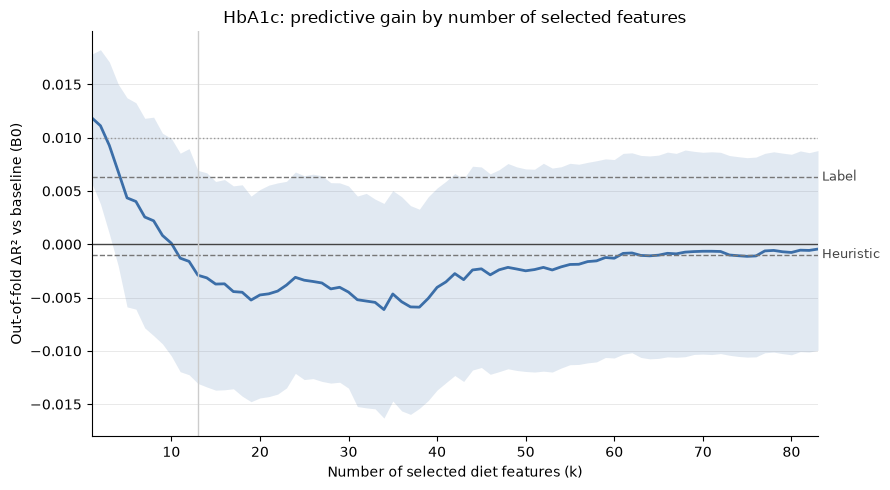

In [48]:
# Plot predictive performances
plot_curve(curve, refs, "HbA1c: predictive gain by number of selected features")

These results above all but confirm it. HbA1C is saturated by a single predictor, which is consistently alcohol. Alcohol is actualy found to slightly lower HBA1C levels in clinical studies, meaning that alcohol being slightly more predictive of HBA1C is not unsurprising. The rapid collapse of performance after including additional predictors implies that these predictors are just capturing noise. All in all, we should not proceed with HBA1C.

# Waist Height Ratio

For continuity's sake, WHR will use the exact same folds and cohort, even though the cohort was tailored to limit diabetes related confounding. Additional concerns for waist height ratio are dieting related, but, as disucssed earlier, we will choose to include these people in the larger analysis (in part because they are the type of people who will be using labels the most) and perform a supplementary analysis without them. 

In [49]:
# Isolate not na waist height ratio
dw = df[df["WHTR"].notna()].reset_index(drop=True)
yw = dw["WHTR"]
print(len(dw), pd.crosstab(dw["FOLD"], "n").T.to_string())

3196 FOLD     0    1    2    3    4
col_0                         
n      643  634  641  643  635


In [50]:
# Display summary of folds
print(dw.groupby("FOLD")["WHTR"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(3))

      count   mean    std    min    50%    max
FOLD                                          
0     643.0  0.597  0.098  0.371  0.591  1.004
1     634.0  0.600  0.102  0.366  0.592  1.019
2     641.0  0.600  0.097  0.382  0.590  0.936
3     643.0  0.594  0.099  0.385  0.588  1.017
4     635.0  0.595  0.097  0.375  0.587  0.949


These distributions look more or less the same (what would be expected from a random split not stratified on anything). As such, we will proceed with analysis.

In [51]:
# Run the five fixed models (2 baselines, label, heuristic, feature-selected 13)
# oof_w stores their out of fold performance
# sel_w stores the selected predicts 
oof_w, sel_w = run_outcome(dw, yw)

# Identify variance for normalization
# Output each model's results
var_w = yw.var(ddof=0)
print(pd.DataFrame([
    {"model": n, "method": m, "R2": 1 - np.mean((yw - p) ** 2) / var_w}
    for (n, m), p in oof_w.items()
]).round(4).to_string(index=False))

print()

# Examine ridge out of fold performance compared to baseline
# First collect ridge predictions
ridge_w = {n: oof_w[(n, "ridge")] for n in ["Label", "Heuristic", "B1", "Selected"]}

# Express gain with respect to baseline
print(delta_r2_curve(yw, ridge_w, oof_w[("B0", "ridge")]).round(4).to_string())

print()

# Isolate features most frequently selected across folds for the 13 feature selected
freq_w = pd.Series([f.removesuffix("_P1K") for fs in sel_w.values() for f in fs]).value_counts()
print(freq_w.head(20).to_string())

    model method     R2
       B0    ols 0.0984
       B0  ridge 0.0986
    Label    ols 0.1058
    Label  ridge 0.1061
Heuristic    ols 0.1084
Heuristic  ridge 0.1087
       B1    ols 0.1220
       B1  ridge 0.1232
 Selected  ridge 0.1331

              dR2      lo      hi
k                                
Label      0.0075 -0.0005  0.0152
Heuristic  0.0101  0.0007  0.0190
B1         0.0246  0.0069  0.0422
Selected   0.0345  0.0197  0.0478

POTA                5
MOIS                5
M201                5
V_DRKGR             5
PF_NUTSDS           5
A_DRINKS            5
FL_APIGEN           5
FL_TOT_ANTHOCYAN    5
SFAT                4
D_CHEESE            4
FL_TOT_ISOFLAV      4
D_YOGURT            3
P204                2
ATOA                2
VB6                 2
FL_QUERCE           1
VC                  1
VB2                 1
PF_SOY              1


The preliminary analysis looks a fair bit stronger. R^2 is marginally higher across all models (as compared to HbA1C), which is what we expected. Moreover, there is a more definitive separation between B0 and the remaining models, especially the selected feature set. We can confirm this by constructing our confidence intervals between each pair.

In [52]:
# For each pair, compute the 95 bootstrap for change in R^2
pairs = [("Label", "Selected"), ("Label", "Heuristic"), ("B1", "Selected")]
for a, b in pairs:
    r = delta_r2_curve(yw, {b: oof_w[(b, "ridge")]}, oof_w[(a, "ridge")])
    print(f"{b} vs {a}: ΔR² {r.loc[b, 'dR2']:.4f}  [{r.loc[b, 'lo']:.4f}, {r.loc[b, 'hi']:.4f}]")

Selected vs Label: ΔR² 0.0270  [0.0133, 0.0394]
Heuristic vs Label: ΔR² 0.0026  [-0.0077, 0.0124]
Selected vs B1: ΔR² 0.0099  [-0.0003, 0.0200]


This looks strong. However, we still need to meet the analysis criteria. Recall that our selection criteria requires that for a LassoCV + Ridge, a 95% paired bootstrap CI should show a significant difference in predictive capacity. Ideally, we would also like to see predictor saturation that exceeds $3$.

In [ ]:
# Perform LassoCV and ridge, compute the paired difference bootstrap
oof_w[("LassoCV", "ridge")], n_lasso_w = lasso_cv_oof(dw, yw)
r = delta_r2_curve(yw, {"LassoCV": oof_w[("LassoCV", "ridge")]}, oof_w[("B0", "ridge")])
print(f"Features per fold: {n_lasso_w}")
print(f"ΔR² vs B0: {r.loc['LassoCV', 'dR2']:.4f} [{r.loc['LassoCV', 'lo']:.4f}, {r.loc['LassoCV', 'hi']:.4f}]")

Features per fold: [31, 30, 25, 31, 22]
ΔR² vs B0: 0.0304 [0.0133, 0.0464]


As we can see, we met both analysis criterias. First, the 95% bootstrap CI for change in R^2 is firmly positive, suggesting that there is a signficant difference in the predictive capacity of a feature selected model compared to the baseline. Unlike HbA1C, the selected number of features for each fold is about 27.8 on average. Based on this analysis, it appears that there is sufficient predictive signal contained in the diet features, and this predictive signal is distributed acrosss predictors. We can confirm this latter statement by considering the size curve:

Best: k = 13, ΔR² 0.0345
Saturation point: k = 7
Label-equivalent size: k = 2
First 3 features per fold: [['MOIS', 'PF_NUTSDS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['MOIS', 'D_CHEESE', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN']]


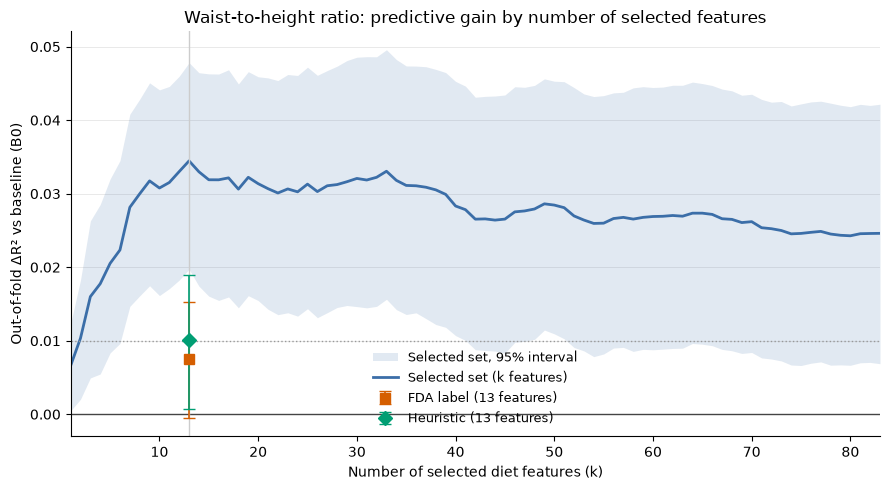

In [ ]:
# Compute size curve, identify best, compare fixed models + featured selected
# To baseline
curve_pred_w, curve_sets_w = size_curve(dw, yw)
curve_w = delta_r2_curve(yw, curve_pred_w, oof_w[("B0", "ridge")])
refs_w = delta_r2_curve(yw, ridge_w, oof_w[("B0", "ridge")])
best_w = curve_w["dR2"].max()

# Output summary statistics of the size curve
# Best k with greatest predictive capacity
# Saturation point --> Where curve begins to plateau
# Label Equivalent Size --> Where predictive capacity is matched for label
# First three features selected for each fold
print(f"Best: k = {curve_w['dR2'].idxmax()}, ΔR² {best_w:.4f}")
print(f"Saturation point: k = {curve_w.index[curve_w['dR2'] >= best_w - 0.01].min()}")
print("First 3 features per fold:", [[f.removesuffix("_P1K") for f in s[3]] for s in curve_sets_w])
plot_curve(curve_w, refs_w, "Waist-to-height ratio: predictive gain by number of selected features")

IMPORTANT: The associated intervals on this visual are paired differences with the baseline. These confidence intervals are valid to compare with the horizontal line 0, but comparing them with each other implicitly assumes observations are independent, even though each person in the data is represented in each estimate, and performance is positively correlated (individuals who are hard to predict for one model are generally hard to predict for the others). It can be shown that positive correlation decreases the spread of the sampling distribution as compared to case where samples are independent. So, while comparing these intervals is not wrong per se, their comparison is unfaithful and misrepresenting the actual comparison we want to make; in particular, they overstate the uncertainty by not accounting for correlation. 

With this in mind, we see that the FDA label actually inconclusively performs better than the baseline, the heursitic performs marginally better than the baseline, but all feature-selected models perform better than the baseline. In particular, the 13-feature selected model performs the best (which is interesting, given this was the number of nutrients on the FDA label). We see a steady increase in predictive capacity, which peaks at 13 features and steadily plateaus; the saturation point is about $7$ features. 

To assess each proposed model against the FDA label, we will produce the same visual but relative to the FDA. This will now provide a faithful way to compare each of our models to the FDA label, where the FDA label is the horizontal zero line. Most of the findings from the previous visual will remain more or less the same; the main goal is to visualize the confidence intervals relative to the label. 

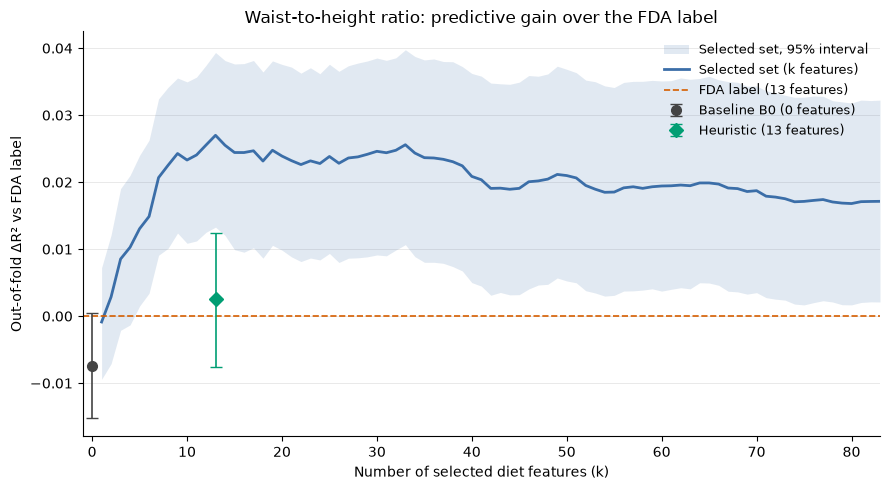

In [66]:
def plot_curve_vs_label(curve, refs, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.fill_between(curve.index, curve["lo"], curve["hi"], color="#3B6EA8", alpha=0.15, linewidth=0,
                    label="Selected set, 95% interval")
    ax.plot(curve.index, curve["dR2"], color="#3B6EA8", linewidth=2, label="Selected set (k features)")
    ax.axhline(0, color="#D55E00", linewidth=1.2, linestyle="--", label="FDA label (13 features)")
    points = {"B0": (0, "#444444", "o", "Baseline B0 (0 features)"),
              "Heuristic": (13, "#009E73", "D", "Heuristic (13 features)")}
    for name, (x, color, marker, label) in points.items():
        est, lo, hi = refs.loc[name, "dR2"], refs.loc[name, "lo"], refs.loc[name, "hi"]
        ax.errorbar(x, est, yerr=[[est - lo], [hi - est]], fmt=marker, color=color,
                    markersize=7, elinewidth=1.2, capsize=4, zorder=3, label=label)
    ax.set_xlim(-1, curve.index.max())
    ax.set_xlabel("Number of selected diet features (k)")
    ax.set_ylabel("Out-of-fold ΔR² vs FDA label")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()

curve_vl_w = delta_r2_curve(yw, curve_pred_w, oof_w[("Label", "ridge")])
refs_vl_w = delta_r2_curve(yw, {m: oof_w[(m, "ridge")] for m in ["B0", "Heuristic"]},
                           oof_w[("Label", "ridge")])
plot_curve_vs_label(curve_vl_w, refs_vl_w, "Waist-to-height ratio: predictive gain over the FDA label")

Here, we see that the baseline performs marginally worse than the label, the heuristic performs about the same as the label, and the feature-selected models perform about the same as the label until about $5$ features, where the feature-selected model begins to perform signficantly better. 

Now, we will move to the frontier.

In [14]:
GAMMAS = np.concatenate([[0], np.logspace(-2, 2, 30)])
w_cost = cost.reindex(POOL).to_numpy(dtype=float)

front_w, preds_w = frontier(dw, yw, oof_w[("B0", "ridge")])

top = front_w.loc[0, "dR2"]
knee = front_w[front_w["on_front"] & (front_w["dR2"] >= top - 0.01)].sort_values("cost").iloc[0]
print(f"γ = 0: cost {front_w.loc[0, 'cost']:.1f}, ΔR² {top:.4f}")
print(f"Knee: γ = {knee.name:.3f}, cost {knee['cost']:.1f}, ΔR² {knee['dR2']:.4f}")
print(f"Label: cost {cost[LABEL].sum()}, ΔR² {refs_w.loc['Label', 'dR2']:.4f}")
print(f"Heuristic: cost {cost[HEURISTIC].sum()}, ΔR² {refs_w.loc['Heuristic', 'dR2']:.4f}")
print(front_w[["cost", "dR2", "lo", "hi", "on_front"]].round(4).to_string())

γ = 0: cost 27.8, ΔR² 0.0345
Knee: γ = 1.610, cost 3.4, ΔR² 0.0265
Label: cost 26, ΔR² 0.0075
Heuristic: cost 9, ΔR² 0.0101
            cost     dR2      lo      hi  on_front
gamma                                             
0.000000    27.8  0.0345  0.0197  0.0478     False
0.010000    27.0  0.0348  0.0196  0.0477     False
0.013738    26.4  0.0354  0.0200  0.0481      True
0.018874    26.4  0.0354  0.0200  0.0481     False
0.025929    26.4  0.0354  0.0200  0.0481     False
0.035622    26.4  0.0354  0.0200  0.0481     False
0.048939    25.0  0.0353  0.0202  0.0478      True
0.067234    24.2  0.0332  0.0177  0.0456      True
0.092367    22.4  0.0329  0.0176  0.0454      True
0.126896    22.4  0.0329  0.0176  0.0454     False
0.174333    20.4  0.0317  0.0168  0.0439     False
0.239503    16.8  0.0325  0.0177  0.0447      True
0.329034    13.6  0.0310  0.0166  0.0434      True
0.452035    10.6  0.0291  0.0151  0.0413      True
0.621017     7.2  0.0287  0.0146  0.0411      True
0.853168 

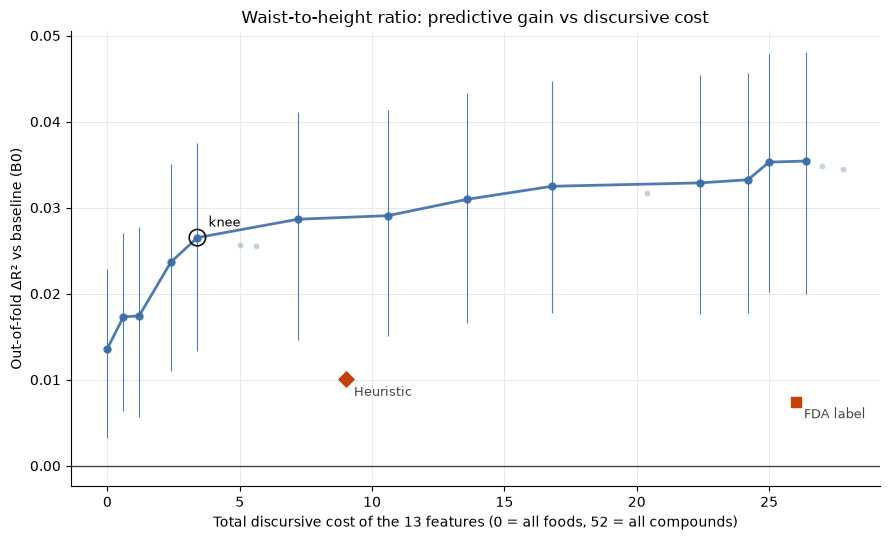

γ   0.092 | cost  23 | out: ['ATOA'] | in: ['PF_SOY']
γ   0.127 | cost  19 | out: ['FL_TOT_ISOFLAV'] | in: ['V_REDOR_OTHER']
γ   0.240 | cost  17 | out: ['SFAT'] | in: ['F_CITMLB']
γ   0.452 | cost  13 | out: ['M201'] | in: ['V_OTHER']
γ   0.621 | cost   6 | out: ['FL_APIGEN', 'FL_TOT_ANTHOCYAN'] | in: ['OILS', 'PF_POULT']
γ   0.853 | cost   5 | out: ['OILS'] | in: ['F_OTHER']
γ   1.610 | cost   3 | out: ['POTA'] | in: ['PF_MEAT']
γ   3.039 | cost   0 | out: ['MOIS'] | in: ['D_MILK']


In [15]:
fig, ax = plt.subplots(figsize=(9, 5.5))
pts = front_w.sort_values("cost")
fr = pts[pts["on_front"]]
ax.scatter(pts["cost"], pts["dR2"], s=18, color="#3B6EA8", alpha=0.3, linewidths=0)
ax.errorbar(fr["cost"], fr["dR2"], yerr=[fr["dR2"] - fr["lo"], fr["hi"] - fr["dR2"]],
            color="#3B6EA8", linewidth=2, marker="o", markersize=5, elinewidth=0.8, capsize=0, alpha=0.9)
for name, feats, marker in [("FDA label", LABEL, "s"), ("Heuristic", HEURISTIC, "D")]:
    x, yv = cost[feats].sum(), refs_w.loc[name.split()[-1].capitalize() if name != "FDA label" else "Label", "dR2"]
    ax.scatter(x, yv, s=60, color="#C2410C", marker=marker, zorder=3)
    ax.annotate(name, (x, yv), xytext=(6, -12), textcoords="offset points", fontsize=9, color="#444444")
ax.scatter(knee["cost"], knee["dR2"], s=140, facecolors="none", edgecolors="#111111", linewidths=1.2, zorder=4)
ax.annotate("knee", (knee["cost"], knee["dR2"]), xytext=(8, 8), textcoords="offset points", fontsize=9)
ax.axhline(0, color="#444444", linewidth=1)
ax.set_xlabel("Total discursive cost of the 13 features (0 = all foods, 52 = all compounds)")
ax.set_ylabel("Out-of-fold ΔR² vs baseline (B0)")
ax.set_title("Waist-to-height ratio: predictive gain vs discursive cost")
ax.grid(color="#E5E5E5", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

sel = front_w.sort_values("cost", ascending=False)
prev = None
for g, row in sel.iterrows():
    cur = set(row["features"])
    if prev is not None and cur != prev:
        print(f"γ {g:7.3f} | cost {row['full_cost']:>3} | out: {sorted(prev - cur)} | in: {sorted(cur - prev)}")
    prev = cur

In [16]:
g_knee, g_food = knee.name, front_w["cost"].idxmin()
tests = [(g_knee, "Label"), (g_knee, "Heuristic"), (g_food, "Label"), (g_food, "Heuristic")]
for g, ref in tests:
    r = delta_r2_curve(yw, {"x": preds_w[g]}, oof_w[(ref, "ridge")])
    print(f"γ {g:.3f} (cost {front_w.loc[g, 'cost']:.1f}) vs {ref}: "
          f"ΔR² {r.loc['x', 'dR2']:.4f}  [{r.loc['x', 'lo']:.4f}, {r.loc['x', 'hi']:.4f}]")

print("\nKnee features:", front_w.loc[g_knee, "features"])
print("All-food features:", front_w.loc[g_food, "features"])

γ 1.610 (cost 3.4) vs Label: ΔR² 0.0190  [0.0064, 0.0306]
γ 1.610 (cost 3.4) vs Heuristic: ΔR² 0.0165  [0.0052, 0.0277]
γ 5.736 (cost 0.0) vs Label: ΔR² 0.0062  [-0.0028, 0.0143]
γ 5.736 (cost 0.0) vs Heuristic: ΔR² 0.0036  [-0.0041, 0.0109]

Knee features: ['MOIS', 'F_CITMLB', 'F_OTHER', 'V_DRKGR', 'V_REDOR_OTHER', 'V_OTHER', 'PF_MEAT', 'PF_POULT', 'PF_SOY', 'PF_NUTSDS', 'D_YOGURT', 'D_CHEESE', 'A_DRINKS']
All-food features: ['F_CITMLB', 'F_OTHER', 'V_DRKGR', 'V_REDOR_OTHER', 'V_OTHER', 'PF_MEAT', 'PF_POULT', 'PF_SOY', 'PF_NUTSDS', 'D_MILK', 'D_YOGURT', 'D_CHEESE', 'A_DRINKS']


In [17]:
knee_cols = ["KCAL"] + cols(front_w.loc[g_knee, "features"])
m = make_model(knee_cols, "ridge").fit(dw, yw)
names = m.named_steps["prep"].get_feature_names_out()
coef = pd.Series(m.named_steps["reg"].coef_, index=names)
print(coef[[n for n in names if n.startswith(("diet", "kcal"))]].sort_values().round(4).to_string())

diet__A_DRINKS_P1K        -0.0087
diet__V_DRKGR_P1K         -0.0062
diet__PF_NUTSDS_P1K       -0.0057
diet__D_YOGURT_P1K        -0.0049
diet__F_CITMLB_P1K        -0.0040
diet__PF_SOY_P1K          -0.0034
diet__V_OTHER_P1K         -0.0033
diet__V_REDOR_OTHER_P1K   -0.0031
diet__F_OTHER_P1K         -0.0019
diet__PF_MEAT_P1K          0.0015
diet__PF_POULT_P1K         0.0023
kcal__KCAL                 0.0056
diet__D_CHEESE_P1K         0.0057
diet__MOIS_P1K             0.0142


In [18]:
r = delta_r2_curve(yw, {"knee": preds_w[g_knee]}, preds_w[g_food])
print(f"Knee vs all-food: ΔR² {r.loc['knee', 'dR2']:.4f}  [{r.loc['knee', 'lo']:.4f}, {r.loc['knee', 'hi']:.4f}]")

Knee vs all-food: ΔR² 0.0129  [0.0037, 0.0214]


In [19]:
pairs = [("FL_TOT_ISOFLAV", "PF_SOY"), ("FL_TOT_ANTHOCYAN", "F_CITMLB"), ("FL_APIGEN", "V_OTHER"),
         ("POTA", "F_OTHER"), ("POTA", "V_OTHER"), ("SFAT", "D_CHEESE"), ("ATOA", "PF_SOY"), ("MOIS", "D_MILK")]
for a, b in pairs:
    print(f"{a:18s} – {b:10s} ρ = {dw[a + '_P1K'].corr(dw[b + '_P1K'], method='spearman'):.2f}")

FL_TOT_ISOFLAV     – PF_SOY     ρ = 0.35
FL_TOT_ANTHOCYAN   – F_CITMLB   ρ = 0.51
FL_APIGEN          – V_OTHER    ρ = 0.48
POTA               – F_OTHER    ρ = 0.43
POTA               – V_OTHER    ρ = 0.37
SFAT               – D_CHEESE   ρ = 0.47
ATOA               – PF_SOY     ρ = 0.25
MOIS               – D_MILK     ρ = -0.06


In [20]:
IMPUTE = "iterative"
alt_h, _ = run_outcome(df, y)
alt_w, _ = run_outcome(dw, yw)
GAMMAS_MAIN = GAMMAS
GAMMAS = np.array([g_knee, g_food])
_, alt_front = frontier(dw, yw, alt_w[("B0", "ridge")])
GAMMAS = GAMMAS_MAIN
IMPUTE = "simple"

rows = []
for outcome, t, main, alt in [("HbA1c", y, oof, alt_h), ("WHtR", yw, oof_w, alt_w)]:
    for m in ["Label", "Heuristic", "Selected"]:
        for version, r in [("simple", main), ("iterative", alt)]:
            d = delta_r2_curve(t, {m: r[(m, "ridge")]}, r[("B0", "ridge")])
            rows.append({"outcome": outcome, "model": m, "imputation": version,
                         "dR2 vs B0": d.loc[m, "dR2"], "lo": d.loc[m, "lo"], "hi": d.loc[m, "hi"]})

for version, kp, base in [("simple", preds_w[g_knee], oof_w), ("iterative", alt_front[g_knee], alt_w)]:
    for ref in ["B0", "Label", "Heuristic"]:
        d = delta_r2_curve(yw, {"knee": kp}, base[(ref, "ridge")])
        rows.append({"outcome": "WHtR", "model": f"Knee vs {ref}", "imputation": version,
                     "dR2 vs B0": d.loc["knee", "dR2"], "lo": d.loc["knee", "lo"], "hi": d.loc["knee", "hi"]})

print(pd.DataFrame(rows).round(4).to_string(index=False))

outcome             model imputation  dR2 vs B0      lo     hi
  HbA1c             Label     simple     0.0063  0.0008 0.0121
  HbA1c             Label  iterative     0.0061  0.0007 0.0117
  HbA1c         Heuristic     simple    -0.0010 -0.0072 0.0046
  HbA1c         Heuristic  iterative    -0.0011 -0.0066 0.0040
  HbA1c          Selected     simple    -0.0029 -0.0131 0.0069
  HbA1c          Selected  iterative    -0.0019 -0.0118 0.0077
   WHtR             Label     simple     0.0075 -0.0005 0.0152
   WHtR             Label  iterative     0.0078  0.0006 0.0151
   WHtR         Heuristic     simple     0.0101  0.0007 0.0190
   WHtR         Heuristic  iterative     0.0104  0.0014 0.0187
   WHtR          Selected     simple     0.0345  0.0197 0.0478
   WHtR          Selected  iterative     0.0347  0.0203 0.0474
   WHtR        Knee vs B0     simple     0.0265  0.0133 0.0375
   WHtR     Knee vs Label     simple     0.0190  0.0064 0.0306
   WHtR Knee vs Heuristic     simple     0.0165  0.0052